In [1]:
import jax
import os

import sys
sys.path.append("../")

%load_ext autoreload
%autoreload 2

import pulse_simulator as ps

/home/andy/Documents/Research/pulse-simulator/.venv/lib/python3.10/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [2]:
from datetime import datetime
import functools
import itertools
import logging
import numpy as np
import pickle as pkl

import qiskit as qk
from qiskit.quantum_info import Operator
from qiskit import pulse
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d

import qutip as qt
import re 
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm, logm
from tqdm import tqdm
import warnings

import matplotlib.pyplot as plt

In [3]:
# Config stuff
jax.config.update("jax_enable_x64", True)
jax.config.update("jax_platform_name", "cpu")
qk_d.array.Array.set_default_backend("jax")

# Pulses

In [4]:
# num_qubits = 10

# backend = qk_fp.GenericBackendV2(
#     num_qubits=num_qubits,
#     basis_gates=["id", "rz", "sx", "x", "ecr"],
#     coupling_map=[[i, i + 1] for i in range(num_qubits - 1)],
#     seed=17,
# )

In [25]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

backend = qk_fp.FakeMumbai()
# backend = qk_fp.FakeManila()
dt = backend.configuration().dt * ns
desired_1qb_duration = 225  # dt
desired_2qb_duration = 225 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb = ps.qiskit_closest_multiple_of_16(desired_2qb_duration * dt / ns, backend)

In [52]:
backend.configuration().coupling_map

[[0, 1],
 [1, 0],
 [1, 2],
 [1, 4],
 [2, 1],
 [2, 3],
 [3, 2],
 [3, 5],
 [4, 1],
 [4, 7],
 [5, 3],
 [5, 8],
 [6, 7],
 [7, 4],
 [7, 6],
 [7, 10],
 [8, 5],
 [8, 9],
 [8, 11],
 [9, 8],
 [10, 7],
 [10, 12],
 [11, 8],
 [11, 14],
 [12, 10],
 [12, 13],
 [12, 15],
 [13, 12],
 [13, 14],
 [14, 11],
 [14, 13],
 [14, 16],
 [15, 12],
 [15, 18],
 [16, 14],
 [16, 19],
 [17, 18],
 [18, 15],
 [18, 17],
 [18, 21],
 [19, 16],
 [19, 20],
 [19, 22],
 [20, 19],
 [21, 18],
 [21, 23],
 [22, 19],
 [22, 25],
 [23, 21],
 [23, 24],
 [24, 23],
 [24, 25],
 [25, 22],
 [25, 24],
 [25, 26],
 [26, 25]]

In [51]:
dir(backend.configuration())

['__class__',
 '__contains__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattr__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_channel_qubit_map',
 '_control_channels',
 '_data',
 '_get_channel_prefix_index',
 '_parse_channels',
 '_qubit_channel_map',
 'acquire',
 'acquisition_latency',
 'backend_name',
 'backend_version',
 'basis_gates',
 'channels',
 'conditional',
 'conditional_latency',
 'control',
 'control_channels',
 'coupling_map',
 'credits_required',
 'default_rep_delay',
 'describe',
 'description',
 'discriminators',
 'drive',
 'dt',
 'dtm',
 'dynamic_reprate_enabled',
 'from_dict',
 'gates',
 'get_channel_qubits',
 'get_qubit_channels',
 'hamiltonian',
 'local',
 'max_experiments',
 'max_shots',
 'm

In [26]:
backend.configuration().hamiltonian

{'description': 'Qubits are modeled as Duffing oscillators. In this case, the system includes higher energy states, i.e. not just |0> and |1>. The Pauli operators are generalized via the following set of transformations:\n\n$(\\mathbb{I}-\\sigma_{i}^z)/2 \\rightarrow O_i \\equiv b^\\dagger_{i} b_{i}$,\n\n$\\sigma_{+} \\rightarrow b^\\dagger$,\n\n$\\sigma_{-} \\rightarrow b$,\n\n$\\sigma_{i}^X \\rightarrow b^\\dagger_{i} + b_{i}$.\n\nQubits are coupled through resonator buses. The provided Hamiltonian has been projected into the zero excitation subspace of the resonator buses leading to an effective qubit-qubit flip-flop interaction. The qubit resonance frequencies in the Hamiltonian are the cavity dressed frequencies and not exactly what is returned by the backend defaults, which also includes the dressing due to the qubit-qubit interactions.\n\nQuantities are returned in angular frequencies, with units 2*pi*GHz.\n\nWARNING: Currently not all system Hamiltonian information is available

In [27]:
# Load shapes
fname_1qb = "../pico-pulses/saved-pulses-2024-02-16/a_single_qubit_gateset_R1e-5.csv"
pico_a = ps.from_csv(fname_1qb)
pico_a = np.vstack([pico_a, 1.0 * np.ones(pico_a.shape[1])])

names_1qb = ["X1", "X2", "SX1", "SX2", "ID1", "ID2"]
angles_1qb = [1.5 * np.pi, 0.5 * np.pi, 1.25 * np.pi, 0.25 * np.pi, 0.2, 0.0]

cal_1qb_robust = ps.calibrate_gateset(
    gateset=pico_a,
    names=names_1qb,
    angles=angles_1qb,
    duration=duration_1qb,
    dt=dt,
)

# defaults
cal_1qb_default = ps.default_single_qubit_gateset(
    names_1qb,
    duration_1qb,
    dt,
)

Storing symbolic pulses...
Adjusting X1 by amplitude 0.20 for angle 1.50π
Adjusting X2 by amplitude 0.20 for angle 0.50π
Adjusting SX1 by amplitude 0.20 for angle 1.25π
Adjusting SX2 by amplitude 0.20 for angle 0.25π
Zero area signal. Adjusting ID1 by amplitude 0.20 (using provided angle).
Adjusting ID2 by amplitude 0.00 for angle 0.00π


In [28]:
def fname(k):
    return f"../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_{k}.csv"

base_2qb = {k: ps.from_csv(fname(k))[0] for k in ["default", "robust"]}
default_2qb = 2 * [base_2qb["default"]]
robust_2qb = 2 * [base_2qb["robust"]]
names_2qb = ["+", "-"]

cal_2qb_default = ps.calibrate_gateset(
    gateset=default_2qb,
    names=names_2qb,
    angles=[0.125 * np.pi, -0.125 * np.pi],
    duration=duration_2qb,
    dt=dt,
    samples=32,
)

cal_2qb_robust = ps.calibrate_gateset(
    gateset=robust_2qb,
    names=names_2qb,
    angles=[0.125 * np.pi, -0.125 * np.pi],
    duration=duration_2qb,
    dt=dt,
    samples=32,
)

Storing symbolic pulses...
Adjusting + by amplitude 0.30 for angle 0.12π
Adjusting - by amplitude-0.30 for angle-0.12π
Storing symbolic pulses...
Adjusting + by amplitude 0.30 for angle 0.12π
Adjusting - by amplitude-0.30 for angle-0.12π


# Circuit

In [90]:
registers = [0, 1, 2, 3, 4, 5]

ising = ps.TransverseIsingModel(quantum_registers=registers)
# circ = ising.second_order_Trotter_unitary()
circ = ising.first_order_Trotter_unitary()

# circ = qk.QuantumCircuit(2, 2)
# [circ.sx(i) for i in range(2)]
# circ.cx(0, 1)

circ.draw()

┌───┐     ┌──────────┐     ┌──────────┐                             
q_0: ┤ H ├──■──┤ Rx(π/10) ├──■──┤ Rz(π/10) ├─────────────────────────────
     ├───┤┌─┴─┐└──────────┘┌─┴─┐└──────────┘┌──────────┐     ┌──────────┐
q_1: ┤ H ├┤ X ├────────────┤ X ├─────■──────┤ Rx(π/10) ├──■──┤ Rz(π/10) ├
     ├───┤└───┘┌──────────┐└───┘   ┌─┴─┐    └──────────┘┌─┴─┐├──────────┤
q_2: ┤ H ├──■──┤ Rx(π/10) ├──■─────┤ X ├────────────────┤ X ├┤ Rz(π/10) ├
     ├───┤┌─┴─┐└──────────┘┌─┴─┐   └───┘    ┌──────────┐└───┘├──────────┤
q_3: ┤ H ├┤ X ├────────────┤ X ├─────■──────┤ Rx(π/10) ├──■──┤ Rz(π/10) ├
     ├───┤└───┘┌──────────┐└───┘   ┌─┴─┐    └──────────┘┌─┴─┐├──────────┤
q_4: ┤ H ├──■──┤ Rx(π/10) ├──■─────┤ X ├────────────────┤ X ├┤ Rz(π/10) ├
     ├───┤┌─┴─┐└──────────┘┌─┴─┐┌──┴───┴───┐            └───┘└──────────┘
q_5: ┤ H ├┤ X ├────────────┤ X ├┤ Rz(π/10) ├─────────────────────────────
     └───┘└───┘            └───┘└──────────┘

In [93]:
qk.QuantumRegister(8)

QuantumRegister(8, 'q144')

In [114]:
from qiskit import QuantumCircuit, transpile

In [139]:
circ = QuantumCircuit(1)
θ = np.pi / 2.01
φ = np.pi / 2.01
λ = np.pi / 2.01
circ.u(θ, φ, λ, 0)
transpile(circ, basis_gates=['cx', 'x', 'sx', 'rz']).draw()


global phase: 6.2754
   ┌───────────┐┌────┐┌────────────┐┌────┐┌────────────┐
q: ┤ Rz(1.563) ├┤ √X ├┤ Rz(4.7046) ├┤ √X ├┤ Rz(10.988) ├
   └───────────┘└────┘└────────────┘└────┘└────────────┘

In [140]:
circ = QuantumCircuit(1)
θ = np.pi / 2 - 5e-1
φ = np.pi / 2 + 1e-1
λ = np.pi / 2 + 1e-1
circ.u(θ, φ, λ, 0)
transpile(circ, basis_gates=['cx', 'x', 'sx', 'rz']).draw()

global phase: 0.1
   ┌────────────┐┌────┐┌────────────┐┌────┐┌────────────┐
q: ┤ Rz(1.6708) ├┤ √X ├┤ Rz(4.2124) ├┤ √X ├┤ Rz(11.096) ├
   └────────────┘└────┘└────────────┘└────┘└────────────┘

In [136]:
circ.x

<bound method QuantumCircuit.x of <qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x7f144807bfd0>>

In [87]:
# dir(backend)

In [95]:
simulator = ps.ExperimentalSimulator(
    registers,
    backend,
)

In [96]:
circ1 = simulator.build_circuit(moments=simulator.build_moments(circ), insert_barriers=True)

/home/andy/Documents/Research/pulse-simulator/.venv/lib/python3.10/site-packages/qiskit/visualization/circuit/matplotlib.py:266: FutureWarning: The default matplotlib drawer scheme will be changed to "iqp" in a following release. To silence this warning, specify the current default explicitly as style="clifford", or the new default as style="iqp".
  self._style, def_font_ratio = load_style(self._style)


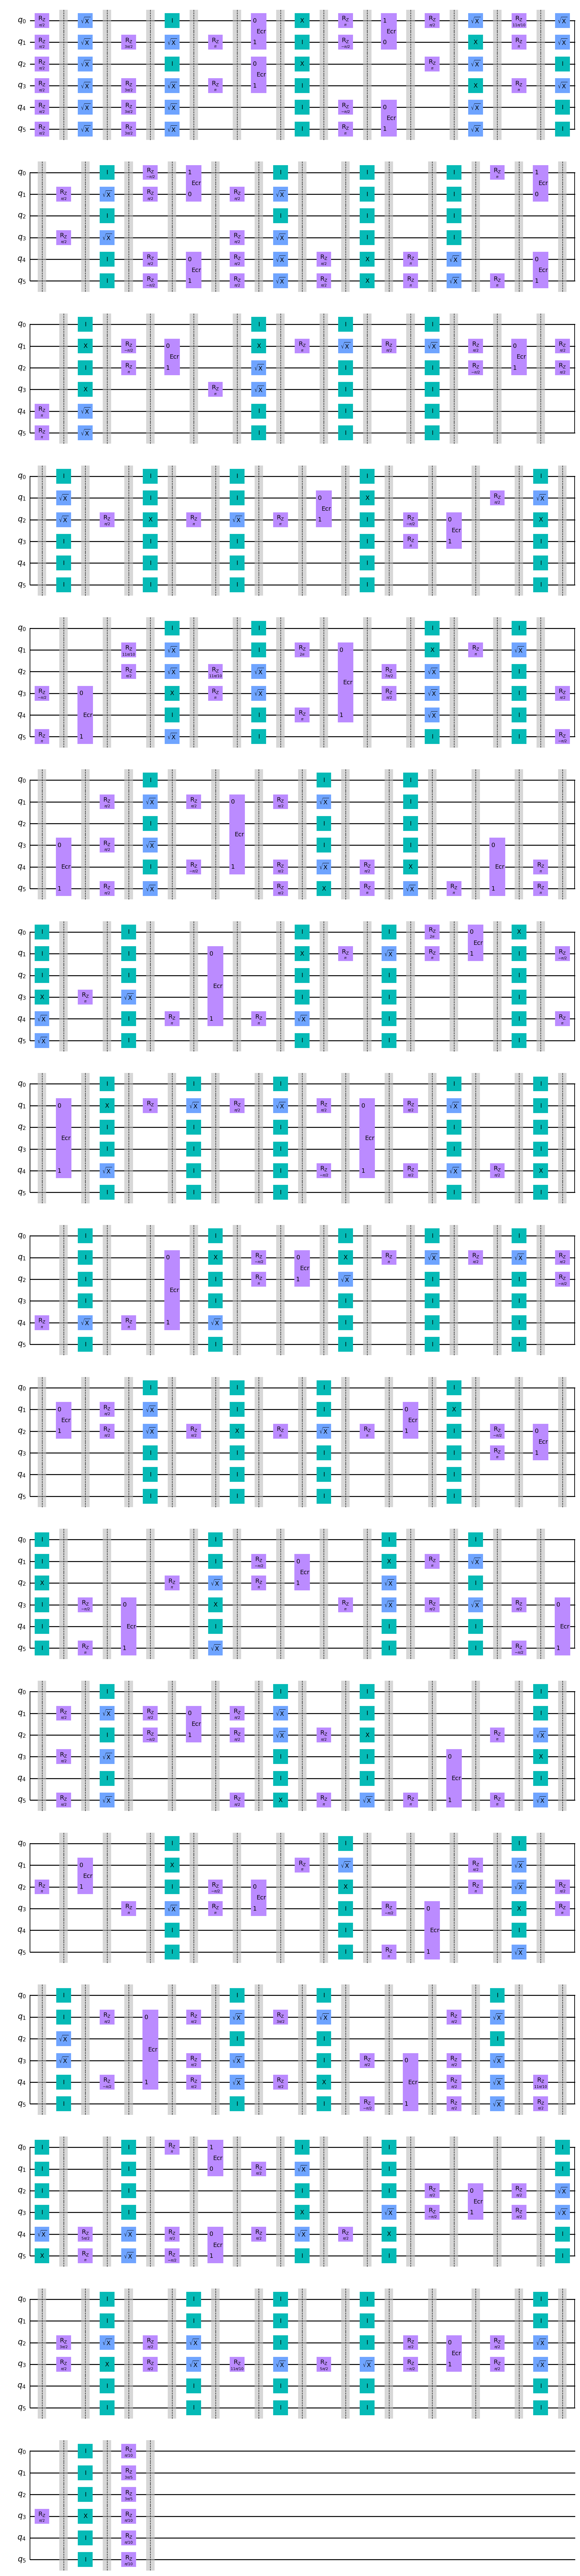

In [97]:
circ1.draw('mpl')

# Simulator

In [44]:
simulator = ps.ExperimentalSimulator(
    registers,
    backend,
)

In this example, we loop over the two qubit gatesets.

In [46]:
fidelities = {} 
cases = ["1-default, 2-default", "1-default, 2-robust", "1-robust, 2-robust", "1-robust, 2-default"]
gateset_pairs = [
    [cal_1qb_default, cal_2qb_default],
    [cal_1qb_default, cal_2qb_robust], 
    [cal_1qb_robust, cal_2qb_robust], 
    [cal_1qb_robust, cal_2qb_default],
]

for case, pair in zip(cases, gateset_pairs):
    gateset1, gateset2 = pair
    res = simulator.simulate_circuit(
        circ, gateset1, gateset2, dt, 
        include_crosstalk=True, atol=1e-12, rtol=1e-12
    )

    moments = simulator.get_moments()

    measure_times = np.cumsum(
        ps.durations_of_moments(moments, duration_1qb, duration_2qb)
    ) * dt

    U_goals = [] 
    for i in range(len(moments)):
        U_goals.append(ps.build_operator(moments[0:i+1], registers))

    # skip initial state in result TODO: should we even return it?
    fids = np.array([ps.operator_fidelity(R, U) for R, U in zip(res[1:], U_goals)])
    fidelities[case] = fids

Exception: Backend edge not found for 4 and 5

In [ ]:
fig, ax = plt.subplots(1)

for case in cases:
    ax.plot(measure_times, 1 - fidelities[case], label=case, marker="o")

ax.set_ylim([1e-12, 1e-1])
ax.set_yscale("log")
ax.set_xlabel("Time (ns)")
ax.set_ylabel("Infidelity")
ax.legend()

In [ ]:
# The circuit used by the simulator is stored and we can view it
simulator.build_circuit(
    insert_barriers=True,
).draw('mpl')

# The schedules and moments are also in there.